In [31]:
import numpy as np
# Setting the random seed, feel free to change it and see different solutions.
np.random.seed(42)

def stepFunction(t):
    if t >= 0:
        return 1
    return 0

def prediction(X, W, b):
    return stepFunction((np.matmul(X,W)+b)[0])

# TODO: Fill in the code below to implement the perceptron trick.
# The function should receive as inputs the data X, the labels y,
# the weights W (as an array), and the bias b,
# update the weights and bias W, b, according to the perceptron algorithm,
# and return W and b.
def perceptronStep(X, y, W, b, learn_rate= 0.01):
    for i in range(len(X)):
        y_hat = prediction(X[i], W, b)  
        if y[i] - y_hat == 1:
            W[0] += X[i][0] * learn_rate
            W[1] += X[i][1] * learn_rate
        elif y[i] - y_hat == -1:
            W[0] -= X[i][0] * learn_rate
            W[1] -= X[i][1] * learn_rate
            b -= learn_rate
    return W, b

# This function runs the perceptron algorithm repeatedly on the dataset,
# and returns a few of the boundary lines obtained in the iterations,
# for plotting purposes.
# Feel free to play with the learning rate and the num_epochs,
# and see your results plotted below.
def trainPerceptronAlgorithm(X, y, learn_rate = 0.01, num_epochs = 25):
    x_min, x_max = min(X.T[0]), max(X.T[0])
    y_min, y_max = min(X.T[1]), max(X.T[1])
    W = np.array(np.random.rand(2,1))
    b = np.random.rand(1)[0] + x_max
    # These are the solution lines that get plotted below.
    boundary_lines = []
    for i in range(num_epochs):
        # In each epoch, we apply the perceptron step.
        W, b = perceptronStep(X, y, W, b, learn_rate)
        boundary_lines.append((-W[0]/W[1], -b/W[1]))
    return boundary_lines


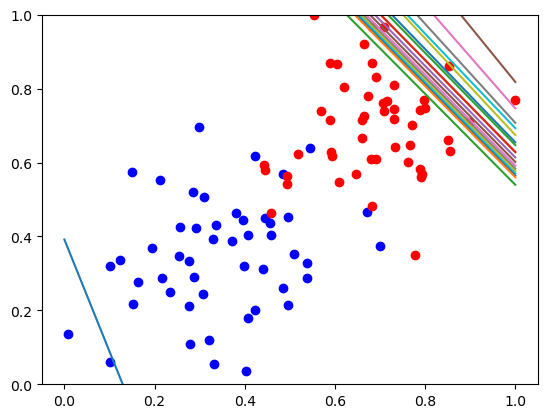

In [30]:
import matplotlib.pyplot as plt
import pandas as pd
PATH = "C:\\Users\\amits\\Desktop\\ML\\למידה עמוקה\\class\\"
df = pd.read_csv(PATH + "pecept_algo_data.csv",header=None)
df.columns = ['x1','x2','y']
boundlines = trainPerceptronAlgorithm(df[['x1','x2']].to_numpy(),df['y'].to_numpy())
                                    

for j in range(len(df)):
    plt.plot(df['x1'].iloc[j],df['x2'].iloc[j], 'ro' if df['y'].iloc[j]==0 else 'bo')
for i in range(2,len(boundlines)):
    x = np.linspace(0,1,20)
    y = boundlines[i][0][0]*x+boundlines[i][1][0]
    plt.ylim(0,1)
    plt.plot(x, y)
    